# Wave-3 results report
Presentation only: every number is read from `wave3/results` (and `wave2/results` for the combined forest plot); nothing is re-estimated except the quantities named in each section (block-bootstrap intervals, date-clustered means, per-trade means). Dates are yyyymmdd integers; **dev = 2022-01-03 to 2023-12-29, test = 2024** (shaded light grey and labelled *test* in every time-series figure). Wave-2 development ends 2024-06-28 and its holdout is 2024-07 to 2024-12. Returns are daily excess returns on a $1M reference account unless stated.

Style: NeurIPS-2025 plot and diagram style guides via `research_style.py`. Each figure has a one-sentence message above it, is rendered with the shared style, and each saved PNG was checked against the style guide and the source data.

In [1]:
import sys, warnings, pathlib, textwrap
ROOT = pathlib.Path('/Users/nigelli/Desktop/lp work')
sys.path.insert(0, str(ROOT / 'wave2')); sys.path.insert(0, str(ROOT))
import analysis
import research_style as rs
rs.setup()
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt, matplotlib.dates as mdates
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle, Ellipse
from matplotlib.lines import Line2D
from IPython.display import Markdown, display
warnings.filterwarnings('ignore')
W2 = ROOT / 'wave2' / 'results'; W3 = ROOT / 'wave3' / 'results'; FIG = ROOT / 'wave3' / 'figures'; FIG.mkdir(exist_ok=True)
DEV_END3 = 20231231
NOTES = {}
def save(fig, name): rs.save(fig, FIG / name); plt.show()
def todt(x): return pd.to_datetime(pd.Series(x).astype(str), format='%Y%m%d')
def shade3(ax): rs.shade_test(ax, pd.Timestamp('2024-01-01'), pd.Timestamp('2024-12-31'), 'test')
def per3(d): return np.where(np.asarray(d) <= DEV_END3, 'dev', 'test')
def skey(v): return v.split('_')[0]
def say(name, text, check=''):
    NOTES[name] = (text, check); display(Markdown(text + (f'\n\n*Data check:* {check}' if check else '')))
def cl_mean_ci(x, cluster):
    """Mean of cluster-averages with 95% interval 1.96*sd/sqrt(k) (clusters = dates)."""
    g = pd.Series(np.asarray(x, float)).groupby(np.asarray(cluster)).mean().dropna()
    k = len(g); m = g.mean(); se = g.std(ddof=1) / np.sqrt(k) if k > 1 else np.nan
    return m, 1.96 * se, k
SC3 = pd.read_csv(W3 / 'scorecard3_daily.csv'); DEC3 = pd.read_csv(W3 / 'decisions3.csv'); EV3 = pd.read_csv(W3 / 'scorecard3_events.csv')
SC2 = pd.read_csv(W2 / 'scorecard_daily.csv'); DEC2 = pd.read_csv(W2 / 'decisions.csv')
ENG = ['s_events', 's3', 's5', 's6', 's7', 's_calendar']
D3 = pd.concat([pd.read_csv(W3 / f'{n}_daily.csv').assign(engine=n) for n in ENG]); D3['period'] = per3(D3.date)
print('variants:', sorted(D3.variant.unique()))
# data check: annualised return recomputed from the engine daily files equals scorecard3_daily
chk = []
for (v, p), g in D3.groupby(['variant', 'period']):
    r = SC3[(SC3.variant == v) & (SC3.period == p)]
    if len(r): chk.append(abs(g.ret.mean() * 252 - r.ann_ret.iloc[0]))
print(f'ann_ret recomputed vs scorecard3_daily: {len(chk)} rows, max abs diff {max(chk):.2e}')


variants: ['S10_tom', 'S1_hedged_10', 'S1_hedged_5', 'S1_unhedged_5', 'S2_big2_h20', 'S2_hedged_h20', 'S2_hedged_h40', 'S3_all_h1', 'S3_all_h5', 'S3_open_h1', 'S3_open_h5', 'S3_so_h1', 'S3_so_h5', 'S4_hedged', 'S5_contango', 'S5_uncond', 'S5_vrp', 'S6_long_top3', 'S6_ls', 'S7_atm_t14', 'S7_atm_t15', 'S7_pin_t14', 'S7_pin_t15', 'S8_nr', 'S9_fomc']
ann_ret recomputed vs scorecard3_daily: 50 rows, max abs diff 9.84e-17


**Figure 0 message:** raw tapes are reduced in DuckDB, run through C++ engines with four execution tiers, scored with a fixed kill rule and multiple-testing controls, and each sample split was frozen by a commit before out-of-sample data were read.

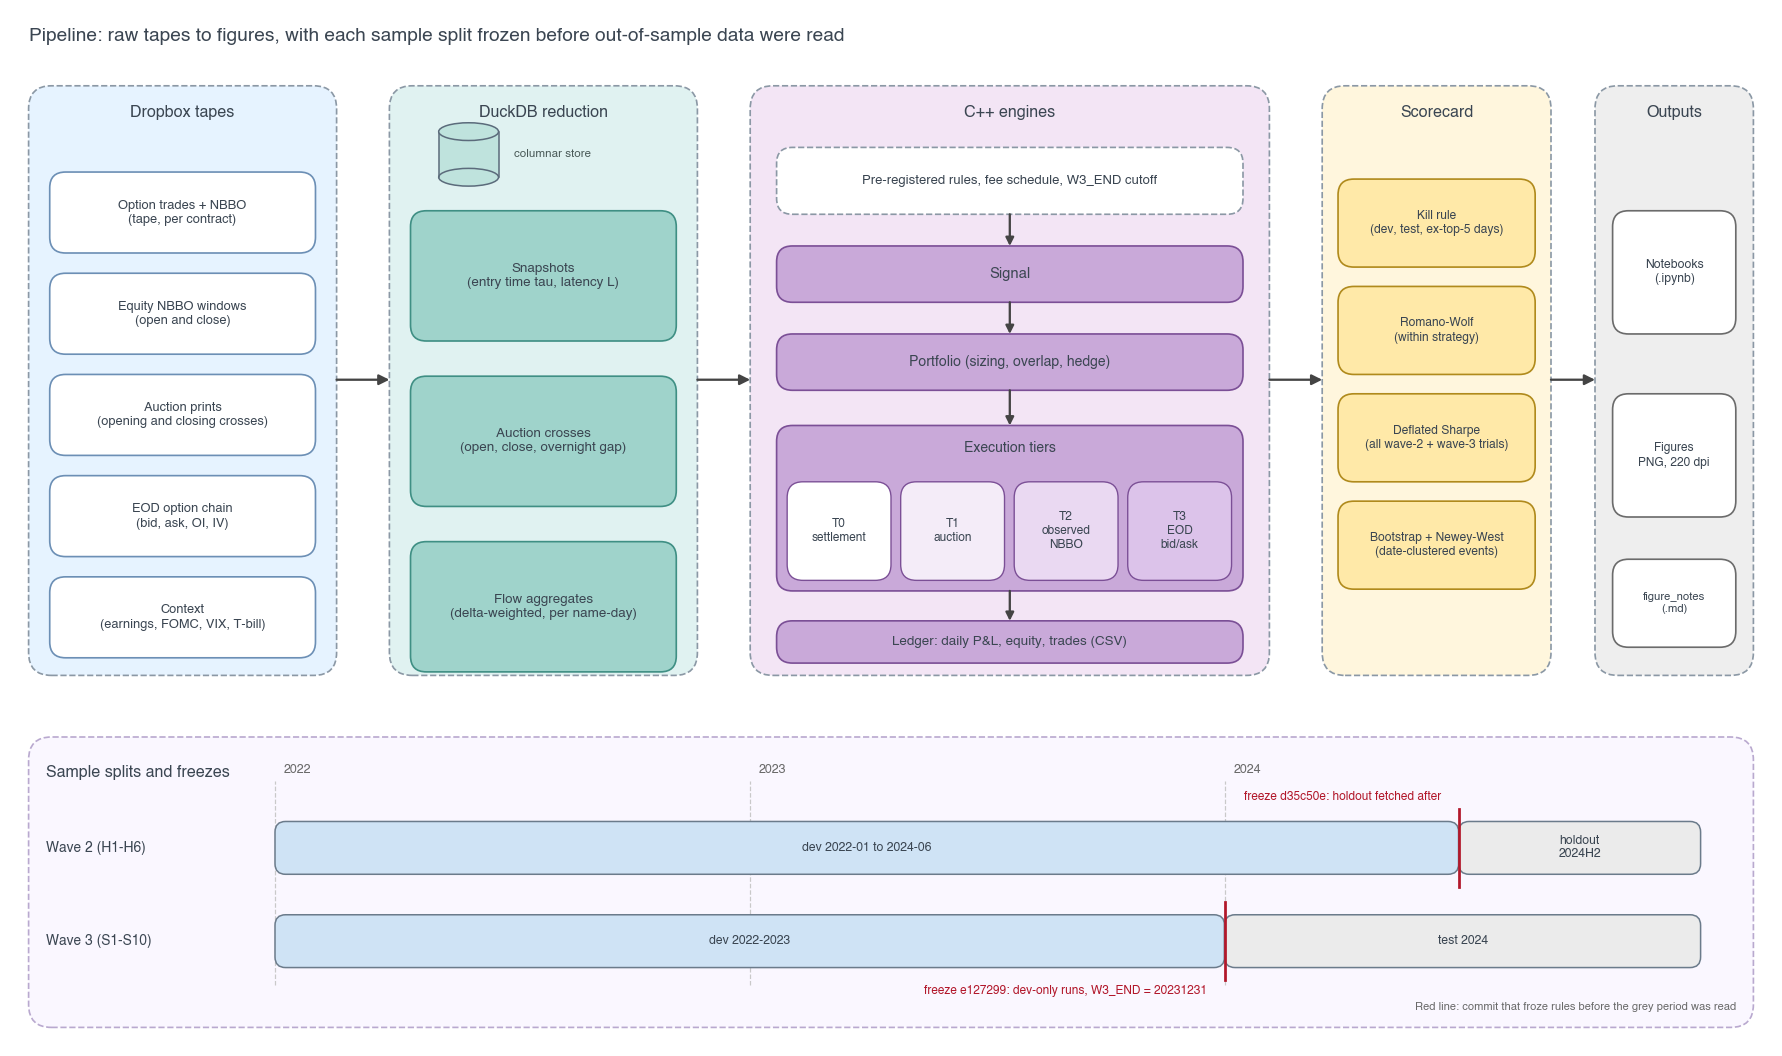

In [2]:
FS = 8.6
fig = plt.figure(figsize=(16, 9.4)); ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, 100); ax.set_ylim(0, 58.75); ax.axis('off')
INKC = '#3b4652'
def zone(x, y, w, h, title, fc, ec='#8b98a5'):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0,rounding_size=1.3', fc=fc, ec=ec, lw=1.1, ls='--', zorder=1))
    ax.text(x + w / 2, y + h - 1.5, title, ha='center', va='center', fontsize=10.5, fontweight='bold', color=INKC, zorder=3)
def box(x, y, w, h, txt, fc='white', ec='#5b6b7b', fs=FS, bold=False, ls='-', lw=1.1, hatch=None, color=INKC):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0,rounding_size=0.9', fc=fc, ec=ec, lw=lw, ls=ls, hatch=hatch, zorder=2))
    ax.text(x + w / 2, y + h / 2, txt, ha='center', va='center', fontsize=fs, fontweight='bold' if bold else 'normal', color=color, zorder=4, linespacing=1.25)
def arrow(p0, p1, ls='-', color='#444444', rad=0., lw=1.5, ms=14):
    ax.add_patch(FancyArrowPatch(p0, p1, arrowstyle='-|>', mutation_scale=ms, lw=lw, ls=ls, color=color, connectionstyle=f'arc3,rad={rad}', zorder=5, shrinkA=0, shrinkB=0))
def cylinder(cx, cy, w, h, fc, ec='#5b6b7b'):
    e = h * .28
    ax.add_patch(Rectangle((cx - w / 2, cy - h / 2 + e / 2), w, h - e, fc=fc, ec='none', zorder=3))
    ax.add_patch(Ellipse((cx, cy - h / 2 + e / 2), w, e, fc=fc, ec=ec, lw=1, zorder=3))
    ax.plot([cx - w / 2] * 2, [cy - h / 2 + e / 2, cy + h / 2 - e / 2], color=ec, lw=1, zorder=3); ax.plot([cx + w / 2] * 2, [cy - h / 2 + e / 2, cy + h / 2 - e / 2], color=ec, lw=1, zorder=3)
    ax.add_patch(Ellipse((cx, cy + h / 2 - e / 2), w, e, fc=fc, ec=ec, lw=1, zorder=4))
ax.text(1, 57.3, 'Pipeline: raw tapes to figures, with each sample split frozen before out-of-sample data were read', fontsize=12.5, fontweight='bold', color=INKC, va='center')
Y0, H = 21.0, 33.5
zone(1, Y0, 17.5, H, 'Dropbox tapes', '#E6F3FF'); zone(21.5, Y0, 17.5, H, 'DuckDB reduction', '#E0F2F1'); zone(42, Y0, 29.5, H, 'C++ engines', '#F3E5F5')
zone(74.5, Y0, 13, H, 'Scorecard', '#FFF6DD'); zone(90, Y0, 9, H, 'Outputs', '#EEEEEE')
tapes = ['Option trades + NBBO\n(tape, per contract)', 'Equity NBBO windows\n(open and close)', 'Auction prints\n(opening and closing crosses)', 'EOD option chain\n(bid, ask, OI, IV)', 'Context\n(earnings, FOMC, VIX, T-bill)']
for i, t in enumerate(tapes): box(2.2, 45.0 - i * 5.75, 15.1, 4.6, t, fc='white', ec='#6c8fb5', fs=8.4)
cylinder(26, 50.6, 3.4, 3.6, '#BFE3DD'); ax.text(28.6, 50.6, 'columnar store', fontsize=7.6, va='center', color='#4a5a58', style='italic')
for i, t in enumerate(['Snapshots\n(entry time tau, latency L)', 'Auction crosses\n(open, close, overnight gap)', 'Flow aggregates\n(delta-weighted, per name-day)']):
    box(22.7, 40.0 - i * 9.4, 15.1, 7.4, t, fc='#9FD3CB', ec='#3f8f84', fs=8.8)
box(43.5, 47.2, 26.5, 3.8, 'Pre-registered rules, fee schedule, W3_END cutoff', fc='white', ec='#8b98a5', ls='--', fs=8.6)
box(43.5, 42.2, 26.5, 3.2, 'Signal', fc='#C9A9D9', ec='#7b4f96', bold=True, fs=9.6)
box(43.5, 37.2, 26.5, 3.2, 'Portfolio (sizing, overlap, hedge)', fc='#C9A9D9', ec='#7b4f96', bold=True, fs=9.2)
ax.add_patch(FancyBboxPatch((43.5, 25.8), 26.5, 9.4, boxstyle='round,pad=0,rounding_size=0.9', fc='#C9A9D9', ec='#7b4f96', lw=1.1, zorder=2))
ax.text(56.75, 33.9, 'Execution tiers', ha='center', va='center', fontsize=9.2, fontweight='bold', color=INKC, zorder=4)
tiers = [('T0', 'settlement'), ('T1', 'auction'), ('T2', 'observed\nNBBO'), ('T3', 'EOD\nbid/ask')]
tfc = ['#FFFFFF', '#F4ECF8', '#EAD9F2', '#DCC3EA']
for i, (a, b) in enumerate(tiers):
    box(44.1 + i * 6.45, 26.4, 5.9, 5.6, f'{a}\n{b}', fc=tfc[i], ec='#7b4f96', fs=7.8, lw=.9)
for p0, p1 in [((56.75, 47.2), (56.75, 45.4)), ((56.75, 42.2), (56.75, 40.4)), ((56.75, 37.2), (56.75, 35.2)), ((56.75, 25.8), (56.75, 24.1))]: arrow(p0, p1, ms=11)
box(43.5, 21.7, 26.5, 2.4, 'Ledger: daily P&L, equity, trades (CSV)', fc='#C9A9D9', ec='#7b4f96', bold=True, fs=8.8)
for i, t in enumerate(['Kill rule\n(dev, test, ex-top-5 days)', 'Romano-Wolf\n(within strategy)', 'Deflated Sharpe\n(all wave-2 + wave-3 trials)', 'Bootstrap + Newey-West\n(date-clustered events)']):
    box(75.4, 44.2 - i * 6.1, 11.2, 5.0, t, fc='#FFE9A8', ec='#b08a1c', fs=7.9)
box(91.0, 40.4, 7.0, 7.0, 'Notebooks\n(.ipynb)', fc='white', ec='#6b6b6b', fs=8.0)
box(91.0, 30.0, 7.0, 7.0, 'Figures\nPNG, 220 dpi', fc='white', ec='#6b6b6b', fs=7.8)
box(91.0, 22.6, 7.0, 5.0, 'figure_notes\n(.md)', fc='white', ec='#6b6b6b', fs=7.4)
ym = 37.8
arrow((18.5, ym), (21.5, ym)); arrow((39.0, ym), (42.0, ym)); arrow((71.5, ym), (74.5, ym)); arrow((87.5, ym), (90.0, ym))
# timeline strip
zone(1, 1.0, 98, 16.5, '', '#FAF7FF', ec='#b9a9cf')
ax.text(2, 15.5, 'Sample splits and freezes', fontsize=10.5, fontweight='bold', color=INKC, va='center')
X0, X1 = 15.0, 96.0
def xd(s):
    t = pd.Timestamp(s); a, b = pd.Timestamp('2022-01-01'), pd.Timestamp('2025-01-01'); return X0 + (t - a) / (b - a) * (X1 - X0)
for yr in (2022, 2023, 2024):
    x = xd(f'{yr}-01-01'); ax.plot([x, x], [3.4, 15.0], color='#c9c9c9', lw=.8, ls='--', zorder=1); ax.text(x + 0.5, 15.6, str(yr), fontsize=8.2, color='#6a6a6a', va='center')
rows = [(9.7, 'Wave 2 (H1-H6)', [('2022-01-01', '2024-06-29', 'dev 2022-01 to 2024-06', '#CFE3F5'), ('2024-06-29', '2025-01-01', 'holdout\n2024H2', rs.TEST_BAND)], '2024-06-29', 'freeze d35c50e: holdout fetched after'),
        (4.4, 'Wave 3 (S1-S10)', [('2022-01-01', '2024-01-01', 'dev 2022-2023', '#CFE3F5'), ('2024-01-01', '2025-01-01', 'test 2024', rs.TEST_BAND)], '2024-01-01', 'freeze e127299: dev-only runs, W3_END = 20231231')]
for y, lab, segs, fz, fl in rows:
    ax.text(2, y + 1.5, lab, fontsize=9, va='center', fontweight='bold', color=INKC)
    for a, b, t, fc in segs:
        ax.add_patch(FancyBboxPatch((xd(a), y), xd(b) - xd(a), 3.0, boxstyle='round,pad=0,rounding_size=0.6', fc=fc, ec='#6b7b8b', lw=1.0, zorder=2))
        ax.text((xd(a) + xd(b)) / 2, y + 1.5, t, ha='center', va='center', fontsize=8.0, color=INKC, zorder=4, linespacing=1.1)
    ax.plot([xd(fz)] * 2, [y - 0.7, y + 3.7], color='#B2182B', lw=1.8, zorder=6)
    ax.text(xd(fz) - 1.0, y + 4.4 if y > 6 else y - 1.3, fl, ha='right', fontsize=7.8, color='#B2182B', va='center', zorder=6)
ax.text(98, 2.0, 'Red line: commit that froze rules before the grey period was read', fontsize=7.3, ha='right', color='#6a6a6a', style='italic')
save(fig, 'fig00_pipeline.png')


In [3]:
say('fig00_pipeline.png', 'Diagram, no estimated numbers: 5 input tapes, 3 DuckDB reductions, 4 execution tiers (T0 settlement, T1 auction, T2 observed NBBO, T3 EOD bid/ask), 4 scorecard tests. Timeline: wave-2 dev 2022-01 to 2024-06 and holdout 2024H2 (freeze commit d35c50e); wave-3 dev 2022-2023 and test 2024 (freeze commit e127299).', 'Dates and commit hashes are those of the git log and the two pre-registrations (wave-2 DEV_END 20240628, wave-3 W3_END 20231231).')


Diagram, no estimated numbers: 5 input tapes, 3 DuckDB reductions, 4 execution tiers (T0 settlement, T1 auction, T2 observed NBBO, T3 EOD bid/ask), 4 scorecard tests. Timeline: wave-2 dev 2022-01 to 2024-06 and holdout 2024H2 (freeze commit d35c50e); wave-3 dev 2022-2023 and test 2024 (freeze commit e127299).

*Data check:* Dates and commit hashes are those of the git log and the two pre-registrations (wave-2 DEV_END 20240628, wave-3 W3_END 20231231).

**Figure 11 message:** across all primaries only a few have a positive annualised excess return in both the development and the out-of-sample period, and almost every 95% bootstrap interval includes zero.

max |point estimate - scorecard ann_ret| = 1.1102230246251565e-16


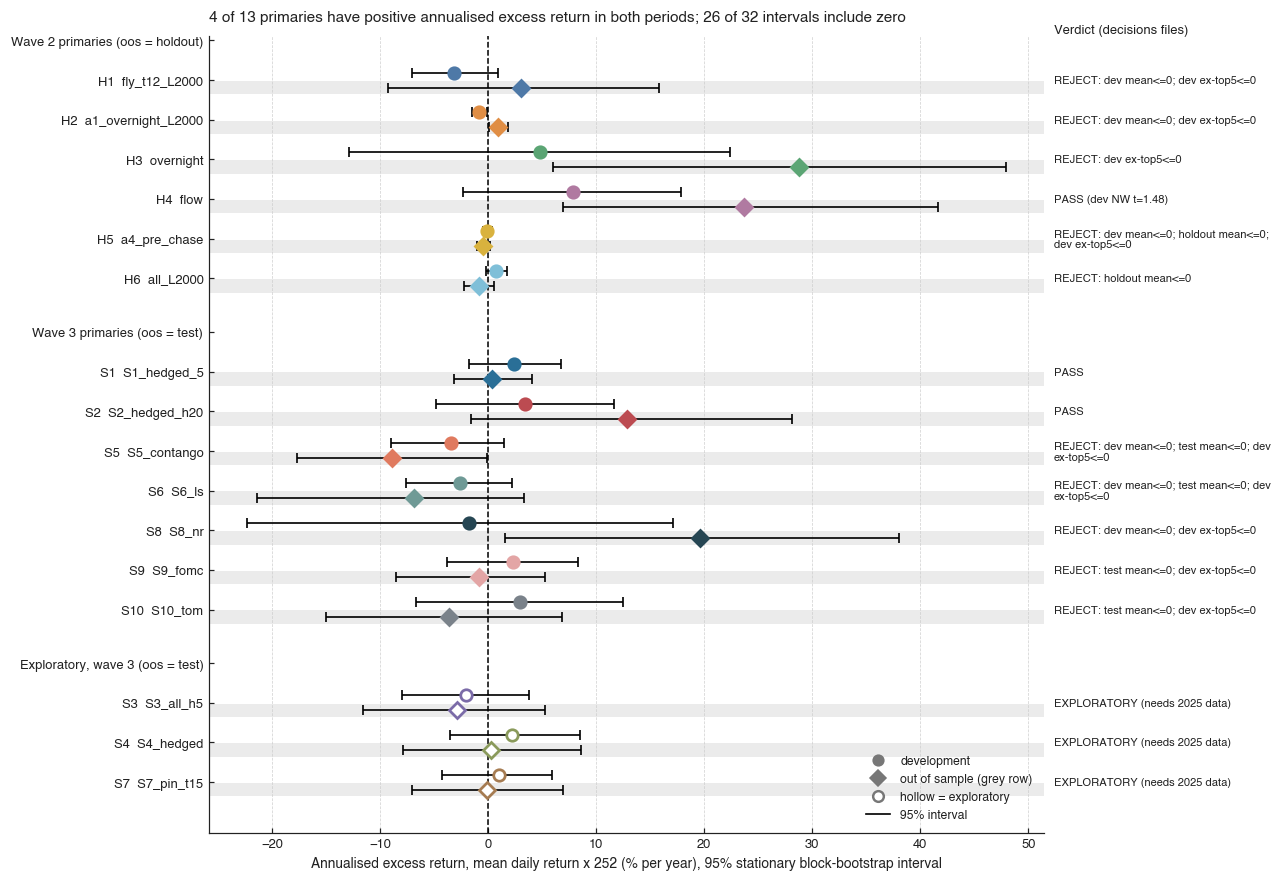

In [4]:
spec2 = [('H1','h1','fly_t12_L2000'), ('H2','h2','a1_overnight_L2000'), ('H3','h3','overnight'), ('H4','h4','flow'), ('H5','h5','a4_pre_chase'), ('H6','h6','all_L2000')]
spec3 = [('S1','s_events','S1_hedged_5'), ('S2','s_events','S2_hedged_h20'), ('S5','s5','S5_contango'), ('S6','s6','S6_ls'), ('S8','s_calendar','S8_nr'), ('S9','s_calendar','S9_fomc'), ('S10','s_calendar','S10_tom')]
specx = [('S3','s3','S3_all_h5'), ('S4','s_events','S4_hedged'), ('S7','s7','S7_pin_t15')]
def ci_ann(r):
    r = np.asarray(r, float) * 252
    lo, hi = analysis.block_boot_ci(r, block=10, draws=3000, seed=0)
    return r.mean(), lo, hi
FOR = []
for grp, spec in (('Wave 2 primaries (oos = holdout)', spec2), ('Wave 3 primaries (oos = test)', spec3), ('Exploratory, wave 3 (oos = test)', specx)):
    for key, f, v in spec:
        if key.startswith('H'):
            d = analysis.daily(f); d = d[d.variant == v].sort_values('date'); dv, oo = d[d.period == 'dev'].ret, d[d.period == 'holdout'].ret
            ver = DEC2[(DEC2.strategy == f) & (DEC2.variant == v)].verdict.iloc[0]
        else:
            d = D3[D3.variant == v].sort_values('date'); dv, oo = d[d.period == 'dev'].ret, d[d.period == 'test'].ret
            ver = DEC3[DEC3.variant == v].verdict.iloc[0]
        FOR.append(dict(grp=grp, key=key, variant=v, expl=grp.startswith('Expl'), dev=ci_ann(dv), oos=ci_ann(oo), verdict=ver.strip(), n_dev=len(dv), n_oos=len(oo)))
FOR_DF = pd.DataFrame(FOR)
# data check: point estimates equal the scorecards' ann_ret
mx = 0
for r in FOR:
    if r['key'].startswith('H'):
        f = {k: a for k, a, _ in spec2}[r['key']]
        for per, est in (('dev', r['dev'][0]), ('holdout', r['oos'][0])):
            s = SC2[(SC2.strategy == f) & (SC2.variant == r['variant']) & (SC2.period == per)]
            if len(s): mx = max(mx, abs(s.ann_ret.iloc[0] - est))
    else:
        for per, est in (('dev', r['dev'][0]), ('test', r['oos'][0])):
            s = SC3[(SC3.variant == r['variant']) & (SC3.period == per)]
            mx = max(mx, abs(s.ann_ret.iloc[0] - est))
print('max |point estimate - scorecard ann_ret| =', mx)
fig, ax = plt.subplots(figsize=(13.2, 9.4)); ypos = {}; labels = {}; y = 0; last = None
for grp in FOR_DF.grp.unique():
    labels[y] = grp; y -= 1
    for r in FOR_DF[FOR_DF.grp == grp].itertuples():
        ypos[r.Index] = y; labels[y] = f'{r.key}  {r.variant}'; y -= 1.0
    y -= 0.35
for r in FOR_DF.itertuples():
    y0 = ypos[r.Index]; c = rs.STRAT_COL[r.key]
    ax.axhspan(y0 - .36, y0 - .02, color=rs.TEST_BAND, zorder=0, lw=0)
    for off, (m, lo, hi), mk in ((.19, r.dev, 'o'), (-.19, r.oos, 'D')):
        ax.errorbar(m * 100, y0 + off, xerr=[[(m - lo) * 100], [(hi - m) * 100]], fmt='none', ecolor='k', elinewidth=1.1, capsize=3, capthick=1.1, zorder=3)
        ax.plot(m * 100, y0 + off, marker=mk, ms=7.5, mfc='white' if r.expl else c, mec=c, mew=1.8, ls='none', zorder=4)
    ax.text(1.012, y0, textwrap.fill(r.verdict, 40), transform=ax.get_yaxis_transform(), fontsize=7.3, va='center', ha='left', color=rs.INK)
ax.axvline(0, color='k', lw=1, ls='--', zorder=2)
ax.set_yticks(list(labels)); ax.set_yticklabels(list(labels.values()))
for t, (yy, lab) in zip(ax.get_yticklabels(), labels.items()):
    if yy not in ypos.values(): t.set_fontweight('bold'); t.set_fontstyle('italic')
ax.grid(axis='y', visible=False); ax.set_xlabel('Annualised excess return, mean daily return x 252 (% per year), 95% stationary block-bootstrap interval')
ax.text(1.012, 1.0, 'Verdict (decisions files)', transform=ax.transAxes, fontsize=8.5, fontweight='bold', va='bottom')
hs = [Line2D([], [], marker='o', ls='none', mfc='#777', mec='#777', ms=7, label='development'), Line2D([], [], marker='D', ls='none', mfc='#777', mec='#777', ms=7, label='out of sample (grey row)'),
      Line2D([], [], marker='o', ls='none', mfc='white', mec='#777', mew=1.6, ms=7, label='hollow = exploratory'), Line2D([], [], color='k', lw=1.1, label='95% interval')]
ax.legend(handles=hs, loc='lower right', ncol=1, fontsize=8)
npos = sum(1 for r in FOR if not r['expl'] and r['dev'][0] > 0 and r['oos'][0] > 0); nci0 = sum(1 for r in FOR for k in ('dev','oos') if r[k][1] <= 0 <= r[k][2])
ax.set_title(f'{npos} of 13 primaries have positive annualised excess return in both periods; {nci0} of {2*len(FOR)} intervals include zero', pad=10)
fig.subplots_adjust(right=.70); save(fig, 'fig11_forest_all.png')


In [5]:
def f1(r): return f"{r['dev'][0]*100:.1f}% [{r['dev'][1]*100:.1f}, {r['dev'][2]*100:.1f}] dev, {r['oos'][0]*100:.1f}% [{r['oos'][1]*100:.1f}, {r['oos'][2]*100:.1f}] oos"
say('fig11_forest_all.png', 'Annualised excess return, point estimate [95% stationary block-bootstrap interval, block 10, 3,000 draws] -- ' + '; '.join(f"{r['key']} {r['variant']}{' (exploratory)' if r['expl'] else ''}: {f1(r)}" for r in FOR) + f'. Both periods positive for {npos} of 13 primaries; {nci0} of {2*len(FOR)} intervals include zero.',
    f'Point estimates equal scorecard ann_ret (max abs diff {mx:.1e}). Wave-2 split at 20240628 (analysis.DEV_END), wave-3 at 20231231. Daily returns include zero-return days, as in the scorecards.')


Annualised excess return, point estimate [95% stationary block-bootstrap interval, block 10, 3,000 draws] -- H1 fly_t12_L2000: -3.1% [-7.1, 0.9] dev, 3.0% [-9.2, 15.9] oos; H2 a1_overnight_L2000: -0.8% [-1.5, -0.1] dev, 0.9% [0.1, 1.8] oos; H3 overnight: 4.8% [-12.8, 22.4] dev, 28.8% [6.0, 47.9] oos; H4 flow: 7.8% [-2.4, 17.8] dev, 23.7% [6.9, 41.6] oos; H5 a4_pre_chase: -0.1% [-0.5, 0.4] dev, -0.5% [-1.0, 0.2] oos; H6 all_L2000: 0.8% [-0.2, 1.7] dev, -0.9% [-2.2, 0.5] oos; S1 S1_hedged_5: 2.4% [-1.7, 6.7] dev, 0.4% [-3.2, 4.0] oos; S2 S2_hedged_h20: 3.4% [-4.8, 11.7] dev, 12.8% [-1.6, 28.1] oos; S5 S5_contango: -3.5% [-9.0, 1.4] dev, -8.9% [-17.7, -0.1] oos; S6 S6_ls: -2.6% [-7.6, 2.2] dev, -6.9% [-21.4, 3.3] oos; S8 S8_nr: -1.8% [-22.3, 17.2] dev, 19.6% [1.6, 38.1] oos; S9 S9_fomc: 2.3% [-3.8, 8.3] dev, -0.9% [-8.5, 5.2] oos; S10 S10_tom: 3.0% [-6.7, 12.5] dev, -3.6% [-15.0, 6.9] oos; S3 S3_all_h5 (exploratory): -2.0% [-8.0, 3.8] dev, -2.9% [-11.5, 5.3] oos; S4 S4_hedged (exploratory): 2.2% [-3.5, 8.5] dev, 0.2% [-7.9, 8.6] oos; S7 S7_pin_t15 (exploratory): 1.0% [-4.3, 5.9] dev, -0.1% [-7.1, 6.9] oos. Both periods positive for 4 of 13 primaries; 26 of 32 intervals include zero.

*Data check:* Point estimates equal scorecard ann_ret (max abs diff 1.1e-16). Wave-2 split at 20240628 (analysis.DEV_END), wave-3 at 20231231. Daily returns include zero-return days, as in the scorecards.

**Figure 12 message:** test-period Sharpe is 1.6 to 1.7 for S2, S8 and S3_all_h1 and negative for S5, S6, S9, S10 and S3_all_h5, and for S8 the dev Sharpe (-0.13) has the opposite sign.

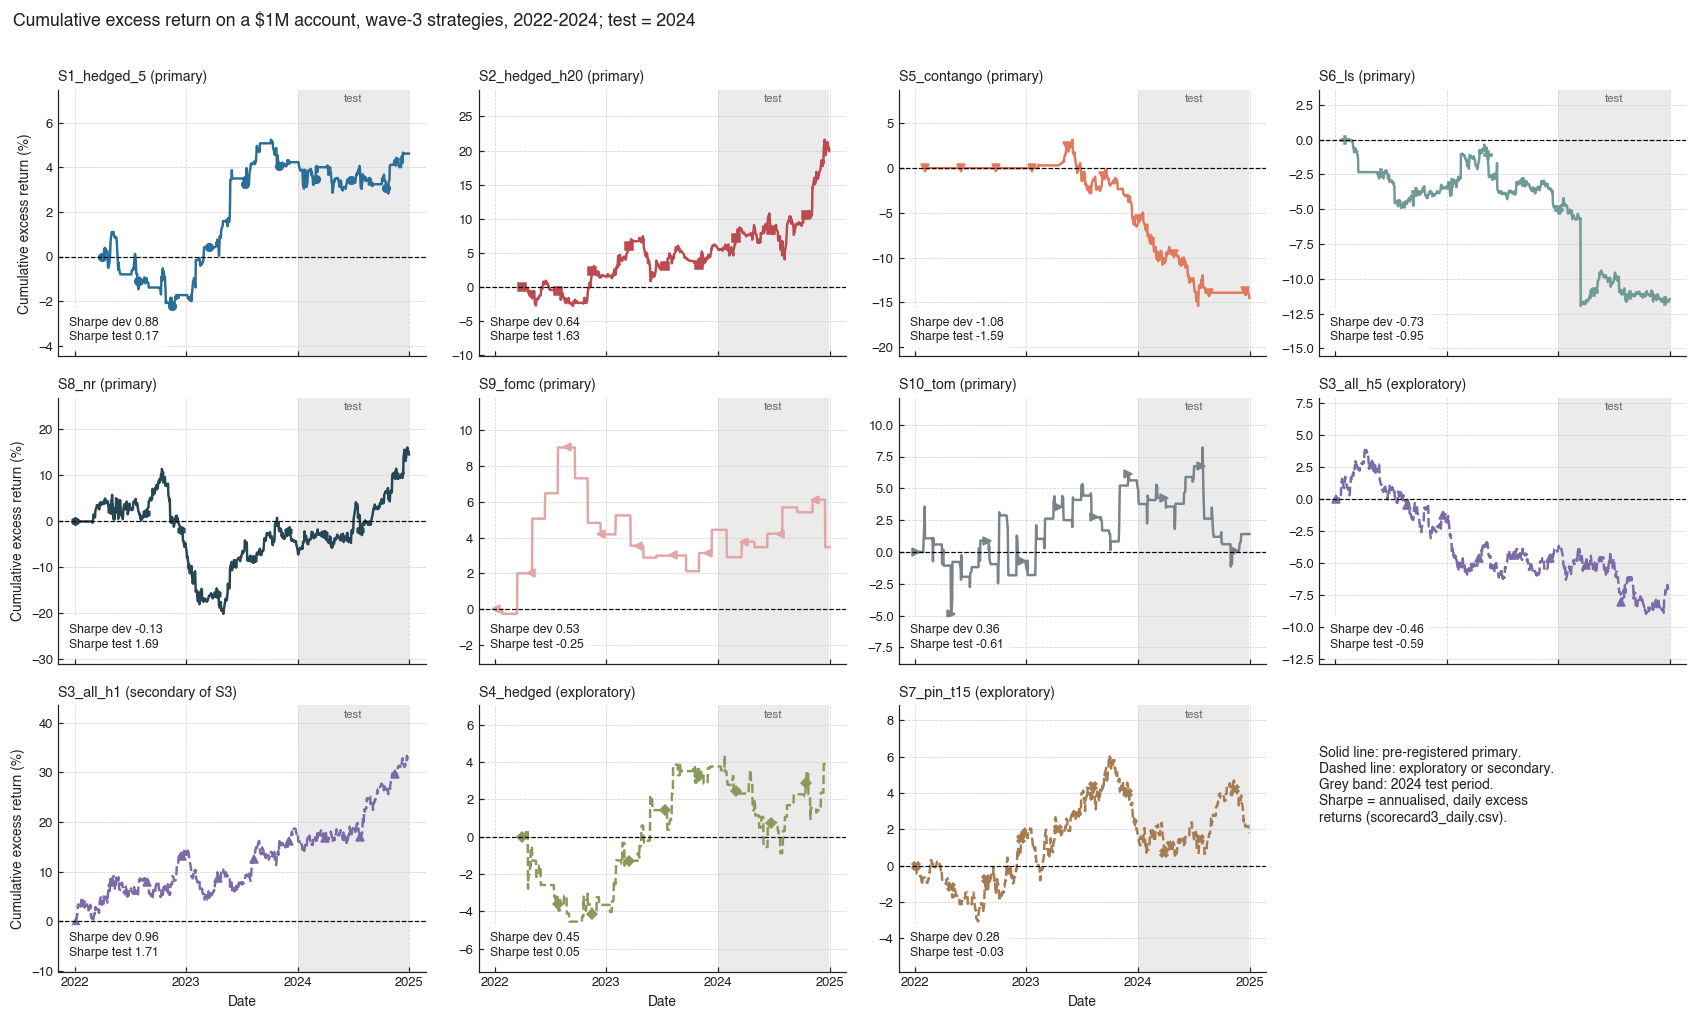

In [6]:
pan = [('S1_hedged_5','primary'), ('S2_hedged_h20','primary'), ('S5_contango','primary'), ('S6_ls','primary'), ('S8_nr','primary'), ('S9_fomc','primary'),
       ('S10_tom','primary'), ('S3_all_h5','exploratory'), ('S3_all_h1','secondary of S3'), ('S4_hedged','exploratory'), ('S7_pin_t15','exploratory')]
fig, axs = plt.subplots(3, 4, figsize=(15.5, 9.4), sharex=True); fin12 = {}
for ax, (v, role) in zip(axs.ravel(), pan):
    k = skey(v); d = D3[D3.variant == v].sort_values('date'); cum = ((1 + d.ret).cumprod() - 1) * 100; fin12[v] = cum.iloc[-1]
    ax.plot(todt(d.date), cum.values, color=rs.STRAT_COL[k], lw=1.6, ls='-' if role == 'primary' else '--', marker=rs.STRAT_MARK[k], markevery=80, ms=5)
    shade3(ax); ax.axhline(0, color='k', lw=.8, ls='--'); ax.margins(y=.3)
    s = {p: SC3[(SC3.variant == v) & (SC3.period == p)].sharpe.iloc[0] for p in ('dev', 'test')}
    ax.text(.03, .05, f"Sharpe dev {s['dev']:.2f}\nSharpe test {s['test']:.2f}", transform=ax.transAxes, va='bottom', fontsize=8, bbox=dict(fc='white', ec='none', alpha=.85), zorder=6)
    ax.set_title(f'{v} ({role})', fontsize=9.3)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y")); ax.xaxis.set_major_locator(mdates.YearLocator())
for ax in axs[:, 0]: ax.set_ylabel('Cumulative excess return (%)')
for ax in axs[2]: ax.set_xlabel('Date')
axs[2, 3].axis('off')
axs[2, 3].text(0, .85, 'Solid line: pre-registered primary.\nDashed line: exploratory or secondary.\nGrey band: 2024 test period.\nSharpe = annualised, daily excess\nreturns (scorecard3_daily.csv).', transform=axs[2, 3].transAxes, va='top', fontsize=9)
fig.suptitle('Cumulative excess return on a $1M account, wave-3 strategies, 2022-2024; test = 2024', x=.01, ha='left', fontsize=11.5)
fig.tight_layout(rect=(0, 0, 1, .97)); save(fig, 'fig12_w3_equity.png')


In [7]:
say('fig12_w3_equity.png', 'Terminal cumulative excess return 2022-2024 (cumulative product of 1 + daily return): ' + '; '.join(f'{v} {x:.1f}%' for v, x in fin12.items()) + '. Sharpe (dev / test): ' + '; '.join(f"{v} {SC3[(SC3.variant==v)&(SC3.period=='dev')].sharpe.iloc[0]:.2f} / {SC3[(SC3.variant==v)&(SC3.period=='test')].sharpe.iloc[0]:.2f}" for v, _ in pan) + '.',
    'Sharpe values are read from scorecard3_daily.csv; curves rebuilt from the engine daily files (ann_ret reproduces the scorecard, see setup cell).')


Terminal cumulative excess return 2022-2024 (cumulative product of 1 + daily return): S1_hedged_5 4.6%; S2_hedged_h20 19.9%; S5_contango -14.5%; S6_ls -11.5%; S8_nr 14.6%; S9_fomc 3.5%; S10_tom 1.4%; S3_all_h5 -7.0%; S3_all_h1 33.4%; S4_hedged 3.9%; S7_pin_t15 1.8%. Sharpe (dev / test): S1_hedged_5 0.88 / 0.17; S2_hedged_h20 0.64 / 1.63; S5_contango -1.08 / -1.59; S6_ls -0.73 / -0.95; S8_nr -0.13 / 1.69; S9_fomc 0.53 / -0.25; S10_tom 0.36 / -0.61; S3_all_h5 -0.46 / -0.59; S3_all_h1 0.96 / 1.71; S4_hedged 0.45 / 0.05; S7_pin_t15 0.28 / -0.03.

*Data check:* Sharpe values are read from scorecard3_daily.csv; curves rebuilt from the engine daily files (ann_ret reproduces the scorecard, see setup cell).

**Figure 13 message:** event-level hedged returns of S1, S2 and S4 are small relative to their date-clustered 95% intervals, and only one variant-period (S1_unhedged_5 in dev) has an interval entirely above zero.

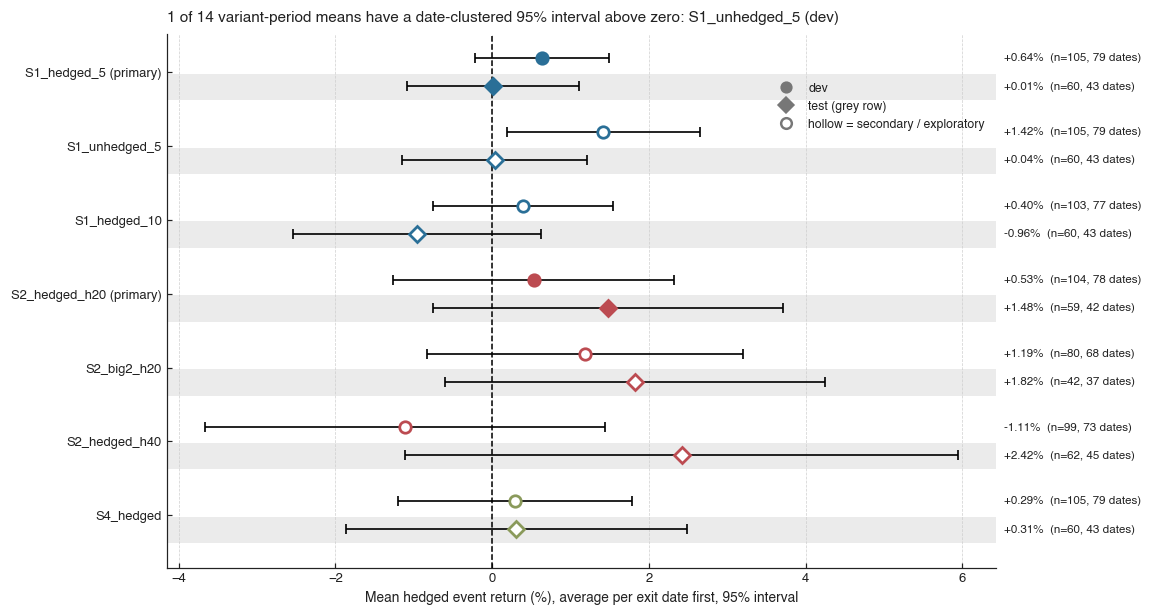

In [8]:
te = pd.read_csv(W3 / 's_events_trades.csv'); te['period'] = per3(te.d_out)
order13 = ['S1_hedged_5','S1_unhedged_5','S1_hedged_10','S2_hedged_h20','S2_big2_h20','S2_hedged_h40','S4_hedged']
primary13 = {'S1_hedged_5','S2_hedged_h20'}; R13 = []
for v in order13:
    g = te[te.variant == v]
    for p in ('dev', 'test'):
        x = g[g.period == p]; m, ci, k = cl_mean_ci(x.r_hedged, x.d_out)
        sc = EV3[(EV3.variant == v) & (EV3.period == p)].iloc[0]
        R13.append(dict(variant=v, period=p, m=m, ci=ci, dates=k, n=len(x), ev_mean=x.r_hedged.mean(), sc_mean=sc['mean'], sc_n=int(sc.n)))
R13 = pd.DataFrame(R13)
fig, ax = plt.subplots(figsize=(11.5, 6.3))
for i, v in enumerate(order13):
    y = -i; k = skey(v); c = rs.STRAT_COL[k]
    ax.axhspan(y - .38, y - .02, color=rs.TEST_BAND, zorder=0, lw=0)
    for off, p, mk in ((.19, 'dev', 'o'), (-.19, 'test', 'D')):
        r = R13[(R13.variant == v) & (R13.period == p)].iloc[0]
        ax.errorbar(r.m * 100, y + off, xerr=r.ci * 100, fmt='none', ecolor='k', elinewidth=1.1, capsize=3, capthick=1.1, zorder=3)
        ax.plot(r.m * 100, y + off, marker=mk, ms=7.5, mfc=c if v in primary13 else 'white', mec=c, mew=1.8, ls='none', zorder=4)
        ax.text(1.01, y + off, f'{r.m*100:+.2f}%  (n={r.n}, {r.dates} dates)', transform=ax.get_yaxis_transform(), fontsize=7.6, va='center')
ax.axvline(0, color='k', lw=1, ls='--', zorder=2)
ax.set_yticks([-i for i in range(len(order13))]); ax.set_yticklabels([v + (' (primary)' if v in primary13 else '') for v in order13]); ax.grid(axis='y', visible=False)
ax.set_xlabel('Mean hedged event return (%), average per exit date first, 95% interval')
ax.legend(handles=[Line2D([], [], marker='o', ls='none', mfc='#777', mec='#777', ms=7, label='dev'), Line2D([], [], marker='D', ls='none', mfc='#777', mec='#777', ms=7, label='test (grey row)'), Line2D([], [], marker='o', ls='none', mfc='white', mec='#777', mew=1.6, ms=7, label='hollow = secondary / exploratory')], loc='upper right', fontsize=8, bbox_to_anchor=(1.0, .93))
posn = [(r.variant, r.period) for r in R13.itertuples() if r.m - r.ci > 0]
ax.set_title(f'{len(posn)} of {len(R13)} variant-period means have a date-clustered 95% interval above zero: ' + ', '.join(f'{v} ({p})' for v, p in posn), pad=8, fontsize=10)
fig.subplots_adjust(right=.78); save(fig, 'fig13_w3_events.png')


In [9]:
pos = [(r.variant, r.period) for r in R13.itertuples() if r.m - r.ci > 0]
say('fig13_w3_events.png', 'Mean hedged event return per variant, date-clustered (average per exit date, then mean over dates), % [95% interval]: ' + '; '.join(f"{r.variant} {r.period} {r.m*100:.2f} [{(r.m-r.ci)*100:.2f}, {(r.m+r.ci)*100:.2f}] (n={r.n} events, {r.dates} dates)" for r in R13.itertuples()) + f'. Intervals strictly above zero: {pos}.',
    f"Event counts equal scorecard3_events.csv (max abs diff {max(abs(R13.n-R13.sc_n))}). Event-weighted means equal the scorecard `mean` column (max abs diff {max(abs(R13.ev_mean-R13.sc_mean)):.1e}); the plotted date-clustered means differ from them (e.g. S1_hedged_5 dev {R13[(R13.variant=='S1_hedged_5')&(R13.period=='dev')].m.iloc[0]*100:.2f}% date-clustered vs {R13[(R13.variant=='S1_hedged_5')&(R13.period=='dev')].ev_mean.iloc[0]*100:.2f}% event-weighted). Period assigned by d_out. S1_unhedged_5 plots r_hedged, which equals r_stock for that variant.")


Mean hedged event return per variant, date-clustered (average per exit date, then mean over dates), % [95% interval]: S1_hedged_5 dev 0.64 [-0.22, 1.49] (n=105 events, 79 dates); S1_hedged_5 test 0.01 [-1.08, 1.11] (n=60 events, 43 dates); S1_unhedged_5 dev 1.42 [0.19, 2.65] (n=105 events, 79 dates); S1_unhedged_5 test 0.04 [-1.14, 1.22] (n=60 events, 43 dates); S1_hedged_10 dev 0.40 [-0.75, 1.55] (n=103 events, 77 dates); S1_hedged_10 test -0.96 [-2.55, 0.62] (n=60 events, 43 dates); S2_hedged_h20 dev 0.53 [-1.26, 2.32] (n=104 events, 78 dates); S2_hedged_h20 test 1.48 [-0.75, 3.71] (n=59 events, 42 dates); S2_big2_h20 dev 1.19 [-0.83, 3.20] (n=80 events, 68 dates); S2_big2_h20 test 1.82 [-0.61, 4.24] (n=42 events, 37 dates); S2_hedged_h40 dev -1.11 [-3.66, 1.44] (n=99 events, 73 dates); S2_hedged_h40 test 2.42 [-1.11, 5.95] (n=62 events, 45 dates); S4_hedged dev 0.29 [-1.21, 1.79] (n=105 events, 79 dates); S4_hedged test 0.31 [-1.87, 2.48] (n=60 events, 43 dates). Intervals strictly above zero: [('S1_unhedged_5', 'dev')].

*Data check:* Event counts equal scorecard3_events.csv (max abs diff 0). Event-weighted means equal the scorecard `mean` column (max abs diff 1.0e-16); the plotted date-clustered means differ from them (e.g. S1_hedged_5 dev 0.64% date-clustered vs 0.46% event-weighted). Period assigned by d_out. S1_unhedged_5 plots r_hedged, which equals r_stock for that variant.

**Figure 14 message:** S5 iron flies lose money when the realised move exceeds about 0.8 of the entry straddle, and the mean return on max loss is negative for every S5 variant in both dev and test.

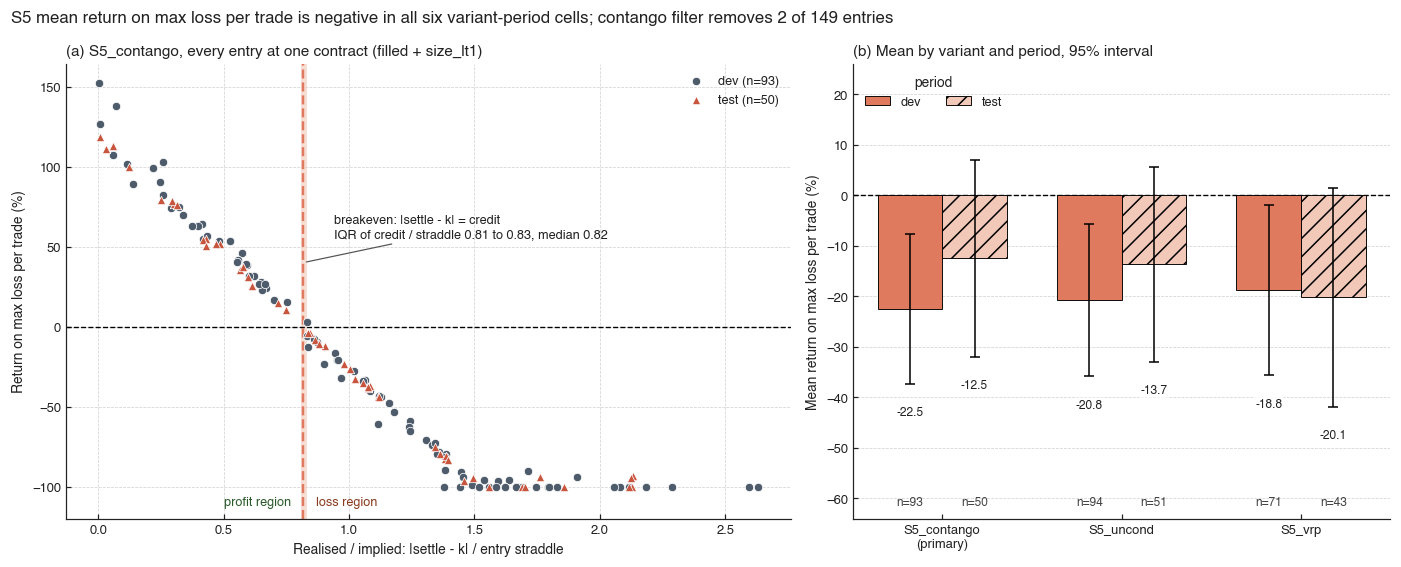

In [10]:
t5 = pd.read_csv(W3 / 's5_trades.csv'); t5 = t5[t5.status.isin(['filled', 'size_lt1'])].copy(); t5['period'] = per3(t5.exp)
t5['ratio'] = (t5.settle - t5.k).abs() / t5.straddle; t5['be'] = t5.credit / t5.straddle
a5 = t5[(t5.variant == 'S5_contango') & t5.ret_on_risk.notna()]
fig, (a, b) = plt.subplots(1, 2, figsize=(12.8, 5.2), gridspec_kw=dict(width_ratios=[1.35, 1]))
q1, q3, med = a5.be.quantile(.25), a5.be.quantile(.75), a5.be.median()
a.axvspan(q1, q3, color='#F2C9B8', alpha=.6, zorder=1, lw=0); a.axvline(med, color=rs.STRAT_COL['S5'], lw=1.6, ls='--', zorder=2)
for p, c, mk in (('dev', rs.DEV_COL, 'o'), ('test', rs.OOS_COL, '^')):
    g = a5[a5.period == p]; a.scatter(g.ratio, g.ret_on_risk * 100, s=30, marker=mk, color=c, edgecolor='white', lw=.5, zorder=3, label=f'{p} (n={len(g)})')
a.axhline(0, color='k', lw=.9, ls='--', zorder=2)
a.annotate(f'breakeven: |settle - k| = credit\nIQR of credit / straddle {q1:.2f} to {q3:.2f}, median {med:.2f}', xy=(med, a.get_ylim()[0] * .0 + 40), xytext=(med + .12, 62), fontsize=8.3, arrowprops=dict(arrowstyle='-', lw=.8, color='#555'), va='center')
a.text(med + .05, -112, 'loss region', fontsize=8.3, color='#8a3b20', style='italic'); a.text(med - .05, -112, 'profit region', fontsize=8.3, color='#2a5a2a', style='italic', ha='right')
a.set_xlabel('Realised / implied: |settle - k| / entry straddle'); a.set_ylabel('Return on max loss per trade (%)'); a.legend(loc='upper right', fontsize=8.3); a.set_ylim(-120, a5.ret_on_risk.max() * 100 + 12)
a.set_title('(a) S5_contango, every entry at one contract (filled + size_lt1)')
out = []
vs5 = ['S5_contango', 'S5_uncond', 'S5_vrp']; w = .36
for i, v in enumerate(vs5):
    for j, (p, hat, col) in enumerate((('dev', '', rs.STRAT_COL['S5']), ('test', '//', '#F2C9B8'))):
        x = t5[(t5.variant == v) & (t5.period == p) & t5.ret_on_risk.notna()]; m, ci, k = cl_mean_ci(x.ret_on_risk, x.exp)
        b.bar(i + (j - .5) * w, m * 100, w, yerr=ci * 100, color=col, hatch=hat, edgecolor='k', lw=.6, capsize=3, error_kw=dict(ecolor='k', lw=1, capthick=1), zorder=3, label=p if i == 0 else None)
        b.text(i + (j - .5) * w, m * 100 - ci * 100 - 4.5, f'{m*100:.1f}', ha='center', va='top', fontsize=7.8, zorder=6, bbox=dict(boxstyle='round,pad=0.12', fc='white', ec='none', alpha=.9)); b.text(i + (j - .5) * w, -62, f'n={len(x)}', ha='center', va='bottom', fontsize=7.8, color='#444')
        out.append(dict(variant=v, period=p, m=m, ci=ci, n=len(x)))
b.axhline(0, color='k', lw=.9, ls='--'); b.set_xticks(range(3)); b.set_xticklabels(['S5_contango\n(primary)', 'S5_uncond', 'S5_vrp']); b.set_ylabel('Mean return on max loss per trade (%)')
b.set_ylim(-64, 26); b.legend(loc='upper left', ncol=2, title='period', fontsize=8.3); b.grid(axis='x', visible=False)
b.set_title('(b) Mean by variant and period, 95% interval')
mn = min(o['m'] - o['ci'] for o in out)
fig.suptitle('S5 mean return on max loss per trade is negative in all six variant-period cells; contango filter removes 2 of 149 entries', x=.01, ha='left', fontsize=11)
fig.tight_layout(); save(fig, 'fig14_s5_vrp.png')


In [11]:
R5 = pd.DataFrame(out); nfil = (pd.read_csv(W3 / 's5_trades.csv').query("variant=='S5_contango'").status == 'filtered').sum()
c5 = {p: (len(a5[a5.period == p]), a5[a5.period == p].ret_on_risk.mean(), (a5[a5.period == p].ratio > a5[a5.period == p].be).mean()) for p in ('dev', 'test')}
say('fig14_s5_vrp.png', 'Mean return on max loss per trade (%), date-clustered 95% interval: ' + '; '.join(f"{r.variant} {r.period} {r.m*100:.1f} [{(r.m-r.ci)*100:.1f}, {(r.m+r.ci)*100:.1f}] (n={r.n})" for r in R5.itertuples()) + f". S5_contango: share of trades whose realised/implied ratio exceeds the trade's own credit/straddle breakeven: dev {c5['dev'][2]:.0%}, test {c5['test'][2]:.0%}; median breakeven ratio {med:.2f}. S5_contango filtered out {nfil} of 149 entries, so S5_contango and S5_uncond have identical daily returns in scorecard3_daily.csv.",
    'Per-trade test uses status in {filled, size_lt1} (amendment B1); period assigned by expiry (exp), which reproduces scorecard3_events means exactly for S5 (dev -22.04%, test -12.81% for S5_contango) with n counted on non-missing ret_on_risk; 3 rows with expiry in 2025 or open_at_end are excluded as missing.')


Mean return on max loss per trade (%), date-clustered 95% interval: S5_contango dev -22.5 [-37.4, -7.7] (n=93); S5_contango test -12.5 [-32.0, 7.0] (n=50); S5_uncond dev -20.8 [-35.8, -5.7] (n=94); S5_uncond test -13.7 [-32.9, 5.6] (n=51); S5_vrp dev -18.8 [-35.6, -2.0] (n=71); S5_vrp test -20.1 [-41.8, 1.5] (n=43). S5_contango: share of trades whose realised/implied ratio exceeds the trade's own credit/straddle breakeven: dev 62%, test 60%; median breakeven ratio 0.82. S5_contango filtered out 2 of 149 entries, so S5_contango and S5_uncond have identical daily returns in scorecard3_daily.csv.

*Data check:* Per-trade test uses status in {filled, size_lt1} (amendment B1); period assigned by expiry (exp), which reproduces scorecard3_events means exactly for S5 (dev -22.04%, test -12.81% for S5_contango) with n counted on non-missing ret_on_risk; 3 rows with expiry in 2025 or open_at_end are excluded as missing.

**Figure 15 message:** for each of the three flow definitions the 1-day hold has a higher Sharpe than the 5-day hold in both dev and test (short_otm dev is about equal), at about five times the fees per day.

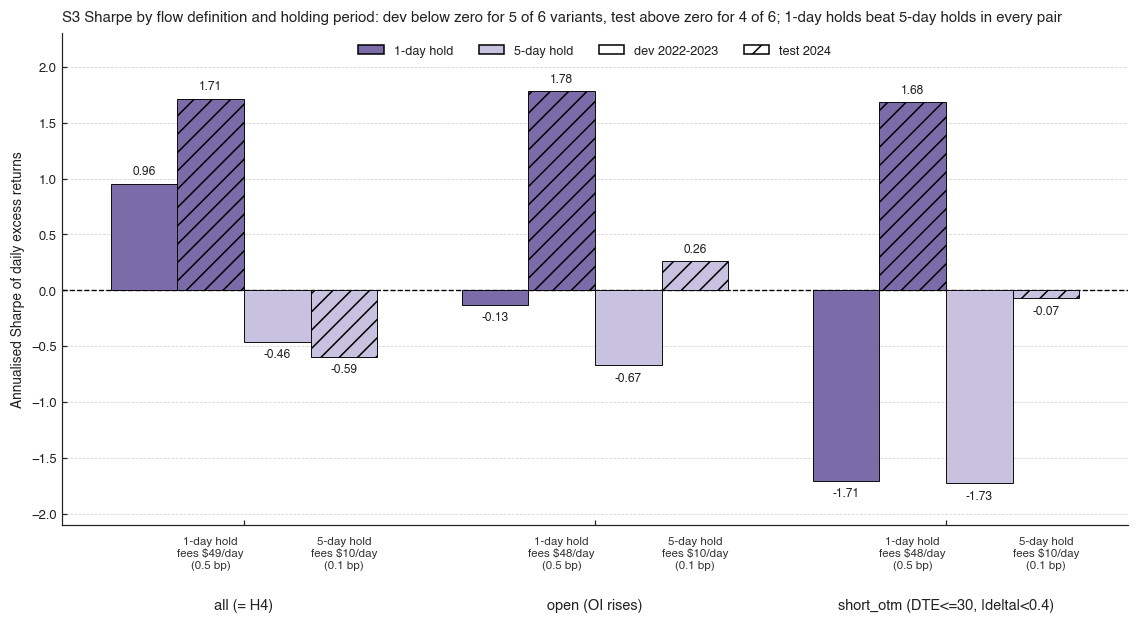

In [12]:
s3t = pd.read_csv(W3 / 's3_trades.csv'); s3t['period'] = per3(s3t.date)
defs = [('all', 'all (= H4)'), ('open', 'open (OI rises)'), ('so', 'short_otm (DTE<=30, |delta|<0.4)')]
fig, ax = plt.subplots(figsize=(12.5, 5.8)); bw = .19; cols = {1: rs.STRAT_COL['S3'], 5: '#C9C1E0'}; fee_rows = []
for gi, (d, dl) in enumerate(defs):
    for hi, h in enumerate((1, 5)):
        v = f'S3_{d}_h{h}'
        for pi, (p, hat) in enumerate((('dev', ''), ('test', '//'))):
            x = gi + (hi * 2 + pi - 1.5) * bw; s = SC3[(SC3.variant == v) & (SC3.period == p)].sharpe.iloc[0]
            ax.bar(x, s, bw, color=cols[h], hatch=hat, edgecolor='k', lw=.6, zorder=3)
            ax.text(x, s + (.06 if s >= 0 else -.06), f'{s:.2f}', ha='center', va='bottom' if s >= 0 else 'top', fontsize=7.8)
        g = s3t[s3t.variant == v]; fee = g.fees.mean(); fee_rows.append(dict(variant=v, fee=fee, borrow=g.borrow.mean(), turn=g.turnover.mean()))
        ax.text(gi + (hi * 2 - .5) * bw, -2.2, f'{h}-day hold\nfees ${fee:,.0f}/day\n({fee/1e6*1e4:.1f} bp)', ha='center', va='top', fontsize=7.6, color='#333')
ax.axhline(0, color='k', lw=.9, ls='--'); ax.set_xticks(range(3)); ax.set_xticklabels([d[1] for d in defs], fontsize=9.5); ax.tick_params(axis='x', pad=48)
ax.set_ylabel('Annualised Sharpe of daily excess returns'); ax.set_ylim(-2.1, 2.3); ax.grid(axis='x', visible=False)
ax.legend(handles=[Rectangle((0, 0), 1, 1, fc=cols[1], ec='k', label='1-day hold'), Rectangle((0, 0), 1, 1, fc=cols[5], ec='k', label='5-day hold'),
                   Rectangle((0, 0), 1, 1, fc='white', ec='k', label='dev 2022-2023'), Rectangle((0, 0), 1, 1, fc='white', ec='k', hatch='//', label='test 2024')], loc='upper center', ncol=4, fontsize=8.3)
FEE = pd.DataFrame(fee_rows).set_index('variant')
shs = SC3[SC3.strategy == 'S3']; nd = int((shs[shs.period == 'dev'].sharpe < 0).sum()); nt = int((shs[shs.period == 'test'].sharpe > 0).sum())
ax.set_title(f'S3 Sharpe by flow definition and holding period: dev below zero for {nd} of 6 variants, test above zero for {nt} of 6; 1-day holds beat 5-day holds in every pair', pad=8, fontsize=9.8)
save(fig, 'fig15_s3_decay.png')


In [13]:
sh = SC3[SC3.strategy == 'S3'].pivot(index='variant', columns='period', values='sharpe')
say('fig15_s3_decay.png', 'S3 Sharpe (dev / test): ' + '; '.join(f"{v} {r.dev:.2f} / {r.test:.2f}" for v, r in sh.iterrows()) + '. Mean fees per day: ' + '; '.join(f"{v} ${r.fee:,.0f}" for v, r in FEE.iterrows()) + f". Mean borrow ${FEE.borrow.mean():,.2f}/day on every variant. S3_all_h5 is the pre-registered exploratory headline; the other five are secondaries.",
    'Fees are the mean of the `fees` column of s3_trades.csv per day over the full 2022-2024 sample (one row per variant-day); bp are relative to the $1M reference account.')


S3 Sharpe (dev / test): S3_all_h1 0.96 / 1.71; S3_all_h5 -0.46 / -0.59; S3_open_h1 -0.13 / 1.78; S3_open_h5 -0.67 / 0.26; S3_so_h1 -1.71 / 1.68; S3_so_h5 -1.73 / -0.07. Mean fees per day: S3_all_h1 $49; S3_all_h5 $10; S3_open_h1 $48; S3_open_h5 $10; S3_so_h1 $48; S3_so_h5 $10. Mean borrow $5.75/day on every variant. S3_all_h5 is the pre-registered exploratory headline; the other five are secondaries.

*Data check:* Fees are the mean of the `fees` column of s3_trades.csv per day over the full 2022-2024 sample (one row per variant-day); bp are relative to the $1M reference account.

**Figure 16 message:** the max-OI strike is usually at or within 5 index points of the at-the-money strike, and the paired pin-minus-ATM iron-fly return per day averages about zero (NW t 0.11 at 14:00 and -0.04 at 15:00).

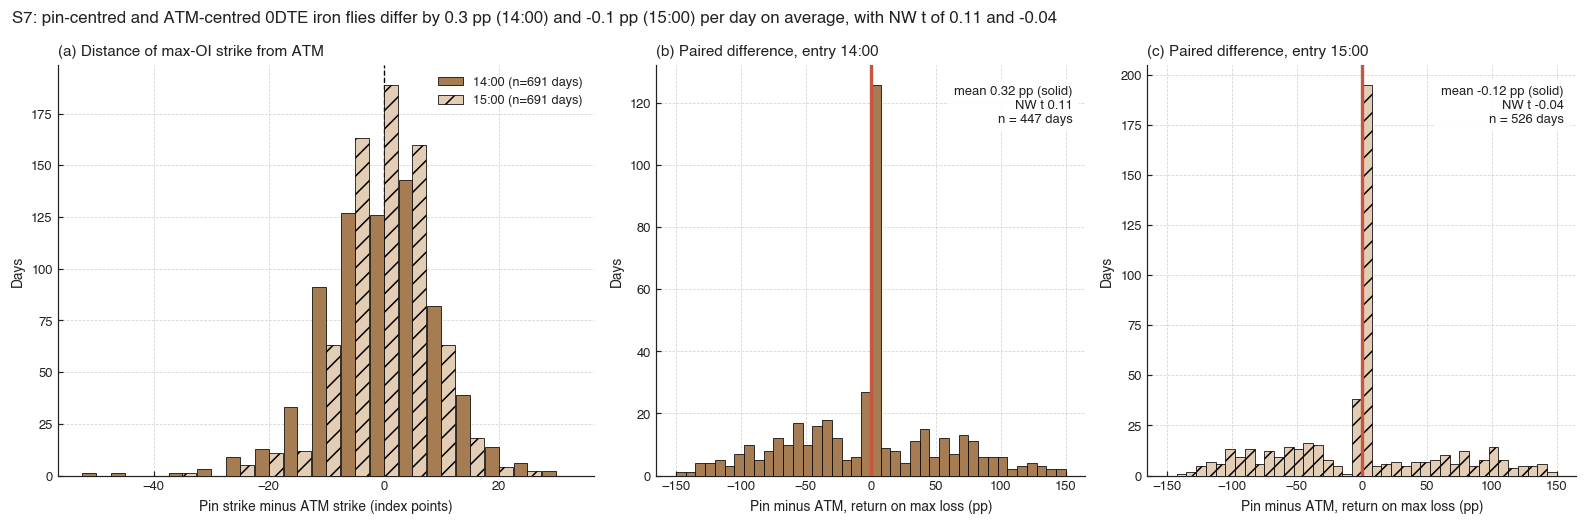

In [14]:
s7 = pd.read_csv(W3 / 's7_trades.csv'); pair = pd.read_csv(W3 / 'scorecard3_s7_pair.csv').set_index('tau')
fig, axs = plt.subplots(1, 3, figsize=(14.5, 4.8), gridspec_kw=dict(width_ratios=[1.25, 1, 1]))
a = axs[0]; bins = np.arange(-52.5, 37.5, 5); st = {}
for k, (tau, hat, col) in enumerate((('t14', '', rs.STRAT_COL['S7']), ('t15', '//', '#E3CDB4'))):
    x = s7[s7.variant == f'S7_pin_{tau}'].dist_atm.dropna(); st[tau] = (len(x), (x == 0).mean(), (x.abs() <= 5).mean(), x.abs().median())
    cnt, _ = np.histogram(x, bins); a.bar(bins[:-1] + 2.5 + (k - .5) * 2.4, cnt, 2.4, color=col, hatch=hat, edgecolor='k', lw=.5, zorder=3, label=f'{tau[1:]}:00 (n={len(x)} days)')
a.axvline(0, color='k', lw=.9, ls='--'); a.set_xlabel('Pin strike minus ATM strike (index points)'); a.set_ylabel('Days'); a.legend(loc='upper right', fontsize=8.3)
a.set_title('(a) Distance of max-OI strike from ATM')
dif = {}
for ax, tau, col in ((axs[1], 't14', rs.STRAT_COL['S7']), (axs[2], 't15', '#E3CDB4')):
    p_ = s7[s7.variant == f'S7_pin_{tau}'].set_index('date').ret_on_risk; a_ = s7[s7.variant == f'S7_atm_{tau}'].set_index('date').ret_on_risk
    d = (p_ - a_).dropna() * 100; dif[tau] = d
    ax.hist(d, bins=np.linspace(-150, 150, 41), color=col, edgecolor='k', lw=.5, hatch='' if tau == 't14' else '//', zorder=3)
    ax.axvline(0, color='k', lw=.9, ls='--'); ax.axvline(d.mean(), color=rs.OOS_COL, lw=2.2, zorder=4)
    ax.text(.97, .95, f"mean {d.mean():.2f} pp (solid)\nNW t {pair.loc[tau, 'nw_t']:.2f}\nn = {len(d)} days", transform=ax.transAxes, ha='right', va='top', fontsize=8.5, bbox=dict(fc='white', ec='none', alpha=.9), zorder=6)
    ax.set_xlabel('Pin minus ATM, return on max loss (pp)'); ax.set_ylabel('Days'); ax.set_title(f'({"b" if tau=="t14" else "c"}) Paired difference, entry {tau[1:]}:00')
fig.suptitle('S7: pin-centred and ATM-centred 0DTE iron flies differ by 0.3 pp (14:00) and -0.1 pp (15:00) per day on average, with NW t of 0.11 and -0.04', x=.01, ha='left', fontsize=11)
fig.tight_layout(); save(fig, 'fig16_s7_pin.png')


In [15]:
say('fig16_s7_pin.png', f"Pin strike equals the ATM strike on {st['t14'][1]:.0%} (14:00) and {st['t15'][1]:.0%} (15:00) of days, and is within 5 points on {st['t14'][2]:.0%} and {st['t15'][2]:.0%}; median |distance| {st['t14'][3]:.0f} and {st['t15'][3]:.0f} points (n={st['t14'][0]} and {st['t15'][0]} days with a pin). Paired pin-minus-ATM difference in return on max loss: 14:00 mean {dif['t14'].mean():.2f} pp, NW t {pair.loc['t14','nw_t']:.2f}, n={len(dif['t14'])}; 15:00 mean {dif['t15'].mean():.2f} pp, NW t {pair.loc['t15','nw_t']:.2f}, n={len(dif['t15'])}.",
    f"Recomputed mean differences equal scorecard3_s7_pair.csv (14:00 {pair.loc['t14','mean_diff']*100:.3f} pp, 15:00 {pair.loc['t15','mean_diff']*100:.3f} pp) and the day counts match ({int(pair.loc['t14','days'])}, {int(pair.loc['t15','days'])}). Days with a missing fill in either leg are dropped from the pair. The spike at zero is days on which the pin strike is the ATM strike (identical trades): {int(sum((d==0).sum() for d in dif.values()))} pair-days in total. Histogram of differences is cut at +/-150 pp for display; {int(sum((abs(d)>150).sum() for d in dif.values()))} pair-days lie outside.")


Pin strike equals the ATM strike on 18% (14:00) and 27% (15:00) of days, and is within 5 points on 57% and 74%; median |distance| 5 and 5 points (n=691 and 691 days with a pin). Paired pin-minus-ATM difference in return on max loss: 14:00 mean 0.32 pp, NW t 0.11, n=447; 15:00 mean -0.12 pp, NW t -0.04, n=526.

*Data check:* Recomputed mean differences equal scorecard3_s7_pair.csv (14:00 0.316 pp, 15:00 -0.124 pp) and the day counts match (447, 526). Days with a missing fill in either leg are dropped from the pair. The spike at zero is days on which the pin strike is the ATM strike (identical trades): 300 pair-days in total. Histogram of differences is cut at +/-150 pp for display; 18 pair-days lie outside.

**Figure 17 message:** neither S6 leg has a mean return on premium distinguishable from zero in dev or test, and among the calendar strategies only S8 has a positive test Sharpe (1.69), after a dev drawdown to about -20% in 2023.

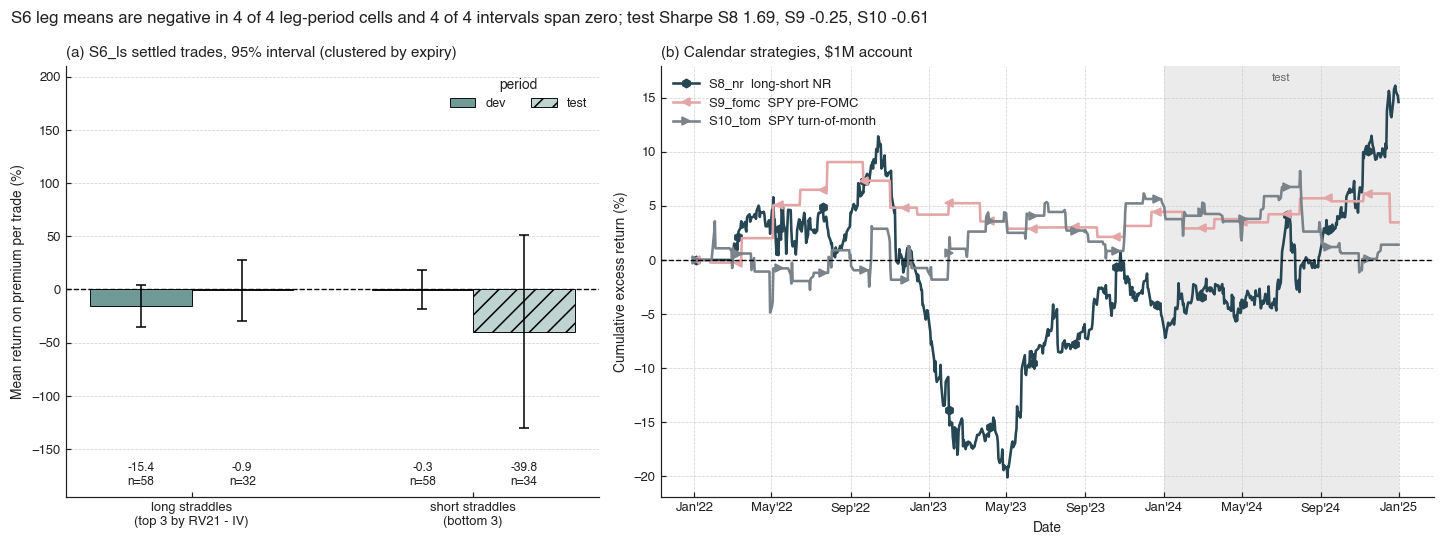

In [16]:
t6 = pd.read_csv(W3 / 's6_trades.csv'); t6 = t6[(t6.variant == 'S6_ls') & (t6.status == 'settled')].copy(); t6['period'] = per3(t6.exp)
fig, (a, b) = plt.subplots(1, 2, figsize=(13.2, 5.0), gridspec_kw=dict(width_ratios=[1, 1.45])); w = .36; r6 = []
for i, (side, lab) in enumerate(((1, 'long leg (top 3 gap)'), (-1, 'short leg (bottom 3 gap)'))):
    for j, (p, hat, col) in enumerate((('dev', '', rs.STRAT_COL['S6']), ('test', '//', '#BFD3D0'))):
        x = t6[(t6.side == side) & (t6.period == p)]; m, ci, k = cl_mean_ci(x.ret_on_premium, x.exp)
        a.bar(i + (j - .5) * w, m * 100, w, yerr=ci * 100, color=col, hatch=hat, edgecolor='k', lw=.6, capsize=3, error_kw=dict(ecolor='k', lw=1, capthick=1), zorder=3, label=p if i == 0 else None)
        a.text(i + (j - .5) * w, -186, f'{m*100:.1f}\nn={len(x)}', ha='center', va='bottom', fontsize=7.8); r6.append(dict(side=side, period=p, m=m, ci=ci, n=len(x), exps=k))
a.axhline(0, color='k', lw=.9, ls='--'); a.set_xticks([0, 1]); a.set_xticklabels(['long straddles\n(top 3 by RV21 - IV)', 'short straddles\n(bottom 3)'])
a.set_ylabel('Mean return on premium per trade (%)'); a.legend(loc='upper right', fontsize=8.3, title='period', ncol=2); a.grid(axis='x', visible=False); a.set_ylim(-195, 210)
a.set_title('(a) S6_ls settled trades, 95% interval (clustered by expiry)')
cal = {}
for v, lab in (('S8_nr', 'S8_nr  long-short NR'), ('S9_fomc', 'S9_fomc  SPY pre-FOMC'), ('S10_tom', 'S10_tom  SPY turn-of-month')):
    k = skey(v); d = D3[D3.variant == v].sort_values('date'); cum = ((1 + d.ret).cumprod() - 1) * 100; cal[v] = cum.iloc[-1]
    b.plot(todt(d.date), cum.values, color=rs.STRAT_COL[k], lw=1.7, marker=rs.STRAT_MARK[k], markevery=45, ms=5.5, label=lab)
shade3(b); b.axhline(0, color='k', lw=.9, ls='--'); b.legend(loc='upper left', fontsize=8.5); b.set_ylabel('Cumulative excess return (%)'); b.set_xlabel('Date')
b.xaxis.set_major_formatter(mdates.DateFormatter("%b'%y")); b.set_title('(b) Calendar strategies, $1M account')
R6_ = pd.DataFrame(r6); nneg = int((R6_.m < 0).sum()); nspan = int(((R6_.m - R6_.ci <= 0) & (R6_.m + R6_.ci >= 0)).sum())
stest = {v: SC3[(SC3.variant == v) & (SC3.period == 'test')].sharpe.iloc[0] for v in cal}
fig.suptitle(f'S6 leg means are negative in {nneg} of 4 leg-period cells and {nspan} of 4 intervals span zero; test Sharpe S8 {stest["S8_nr"]:.2f}, S9 {stest["S9_fomc"]:.2f}, S10 {stest["S10_tom"]:.2f}', x=.01, ha='left', fontsize=11)
fig.tight_layout(); save(fig, 'fig17_s6_s8_calendar.png')


In [17]:
R6 = pd.DataFrame(r6); nm = {1: 'long', -1: 'short'}
say('fig17_s6_s8_calendar.png', 'S6_ls mean return on premium per settled trade, % [95% interval clustered by expiry]: ' + '; '.join(f"{nm[r.side]} {r.period} {r.m*100:.1f} [{(r.m-r.ci)*100:.1f}, {(r.m+r.ci)*100:.1f}] (n={r.n}, {r.exps} expiries)" for r in R6.itertuples()) + '. Terminal cumulative excess return 2022-2024: ' + '; '.join(f'{v} {x:.1f}%' for v, x in cal.items()) + '. Sharpe dev / test: ' + '; '.join(f"{v} {SC3[(SC3.variant==v)&(SC3.period=='dev')].sharpe.iloc[0]:.2f} / {SC3[(SC3.variant==v)&(SC3.period=='test')].sharpe.iloc[0]:.2f}" for v in cal) + '.',
    f"Settled S6_ls trades {len(t6)} (dev {(t6.period=='dev').sum()}, test {(t6.period=='test').sum()}) equal the event counts in scorecard3_events.csv (116, 66) with period assigned by expiry; the settled long and short legs use `ret_on_premium` as stored (per-trade, before aggregation).")


S6_ls mean return on premium per settled trade, % [95% interval clustered by expiry]: long dev -15.4 [-35.0, 4.2] (n=58, 20 expiries); long test -0.9 [-29.6, 27.7] (n=32, 12 expiries); short dev -0.3 [-18.4, 17.9] (n=58, 20 expiries); short test -39.8 [-130.3, 50.8] (n=34, 12 expiries). Terminal cumulative excess return 2022-2024: S8_nr 14.6%; S9_fomc 3.5%; S10_tom 1.4%. Sharpe dev / test: S8_nr -0.13 / 1.69; S9_fomc 0.53 / -0.25; S10_tom 0.36 / -0.61.

*Data check:* Settled S6_ls trades 182 (dev 116, test 66) equal the event counts in scorecard3_events.csv (116, 66) with period assigned by expiry; the settled long and short legs use `ret_on_premium` as stored (per-trade, before aggregation).

## Decisions (decisions3.csv)

In [18]:
D = DEC3.copy()
def pc(v): return '' if pd.isna(v) else f'{v*100:.2f}%'
def nf(v, d=2): return '' if pd.isna(v) else f'{v:.{d}f}'
tab = '| strategy | variant | verdict | dev ann | dev Sharpe | dev NW t | dev DSR | RW p (dev) | test ann | test Sharpe | test NW t | alpha dev (ann) | beta dev |\n|---|---|---|---|---|---|---|---|---|---|---|---|---|\n'
for r in D.itertuples(): tab += f'| {r.strategy} | {r.variant} | {r.verdict.strip()} | {pc(r.dev_ann)} | {nf(r.dev_sharpe)} | {nf(r.dev_nw_t)} | {nf(r.dev_dsr,3)} | {nf(r.rw_p_dev,3)} | {pc(r.test_ann)} | {nf(r.test_sharpe)} | {nf(r.test_nw_t)} | {pc(r.alpha_dev)} | {nf(r.beta_dev,3)} |\n'
tab2 = '\n\n| strategy | variant | events dev | mean dev | t dev | events test | mean test | t test |\n|---|---|---|---|---|---|---|---|\n'
for r in D[D.ev_n_dev.notna()].itertuples(): tab2 += f'| {r.strategy} | {r.variant} | {int(r.ev_n_dev)} | {pc(r.ev_mean_dev)} | {nf(r.ev_t_dev)} | {int(r.ev_n_test)} | {pc(r.ev_mean_test)} | {nf(r.ev_t_test)} |\n'
display(Markdown(tab + tab2))


| strategy | variant | verdict | dev ann | dev Sharpe | dev NW t | dev DSR | RW p (dev) | test ann | test Sharpe | test NW t | alpha dev (ann) | beta dev |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| S1 | S1_hedged_5 | PASS | 2.41% | 0.88 | 1.08 | 0.094 | 0.360 | 0.40% | 0.17 | 0.18 | 2.35% | 0.011 |
| S2 | S2_hedged_h20 | PASS | 3.38% | 0.64 | 0.87 | 0.050 | 0.407 | 12.82% | 1.63 | 1.65 | 3.42% | -0.008 |
| S5 | S5_contango | REJECT: dev mean<=0; test mean<=0; dev ex-top5<=0 | -3.46% | -1.08 | -1.37 | 0.000 | 0.232 | -8.85% | -1.59 | -1.81 | -3.32% | -0.025 |
| S6 | S6_ls | REJECT: dev mean<=0; test mean<=0; dev ex-top5<=0 | -2.56% | -0.73 | -1.06 | 0.000 | 0.297 | -6.90% | -0.95 | -1.00 | -2.51% | -0.009 |
| S8 | S8_nr | REJECT: dev mean<=0; dev ex-top5<=0 | -1.79% | -0.13 | -0.20 | 0.004 | 0.847 | 19.64% | 1.69 | 1.80 | -1.59% | -0.062 |
| S9 | S9_fomc | REJECT: test mean<=0; dev ex-top5<=0 | 2.28% | 0.53 | 0.74 | 0.041 | 0.460 | -0.87% | -0.25 | -0.25 | 2.11% | 0.052 |
| S10 | S10_tom | REJECT: test mean<=0; dev ex-top5<=0 | 2.97% | 0.36 | 0.55 | 0.024 | 0.549 | -3.64% | -0.61 | -0.64 | 2.39% | 0.179 |
| S3 | S3_all_h5 | EXPLORATORY (needs 2025 data) | -2.03% | -0.46 | -0.64 | 0.001 | 0.741 | -2.92% | -0.59 | -0.65 | -2.00% | -0.009 |
| S4 | S4_hedged | EXPLORATORY (needs 2025 data) | 2.24% | 0.45 | 0.66 | 0.030 | 0.494 | 0.23% | 0.05 | 0.05 | 2.27% | -0.006 |
| S7 | S7_pin_t15 | EXPLORATORY (needs 2025 data) | 1.05% | 0.28 | 0.38 | 0.018 | 0.963 | -0.09% | -0.03 | -0.03 | 1.06% | -0.002 |


| strategy | variant | events dev | mean dev | t dev | events test | mean test | t test |
|---|---|---|---|---|---|---|---|
| S1 | S1_hedged_5 | 105 | 0.46% | 1.47 | 60 | 0.06% | 0.02 |
| S2 | S2_hedged_h20 | 104 | 0.50% | 0.59 | 59 | 1.55% | 1.32 |
| S5 | S5_contango | 93 | -22.04% | -2.99 | 50 | -12.81% | -1.27 |
| S6 | S6_ls | 116 | -7.19% | -1.12 | 66 | -17.89% | -0.97 |
| S4 | S4_hedged | 105 | 0.41% | 0.38 | 60 | 0.07% | 0.28 |
| S7 | S7_pin_t15 | 367 | 0.55% | 0.14 | 185 | -1.18% | -0.22 |


## Figure notes file

In [19]:
lines = ['# Wave-3 figure notes', '', 'Generated by `wave3/notebooks/wave3_report.ipynb`. Facts only; no interpretation beyond the numbers.', '']
for k in sorted(NOTES):
    t, c = NOTES[k]; lines.append(f'- **{k}**: {t}' + (f' *Data check:* {c}' if c else ''))
(FIG / 'figure_notes.md').write_text('\n'.join(lines) + '\n'); print(open(FIG / 'figure_notes.md').read()[:1500])


# Wave-3 figure notes

Generated by `wave3/notebooks/wave3_report.ipynb`. Facts only; no interpretation beyond the numbers.

- **fig00_pipeline.png**: Diagram, no estimated numbers: 5 input tapes, 3 DuckDB reductions, 4 execution tiers (T0 settlement, T1 auction, T2 observed NBBO, T3 EOD bid/ask), 4 scorecard tests. Timeline: wave-2 dev 2022-01 to 2024-06 and holdout 2024H2 (freeze commit d35c50e); wave-3 dev 2022-2023 and test 2024 (freeze commit e127299). *Data check:* Dates and commit hashes are those of the git log and the two pre-registrations (wave-2 DEV_END 20240628, wave-3 W3_END 20231231).
- **fig11_forest_all.png**: Annualised excess return, point estimate [95% stationary block-bootstrap interval, block 10, 3,000 draws] -- H1 fly_t12_L2000: -3.1% [-7.1, 0.9] dev, 3.0% [-9.2, 15.9] oos; H2 a1_overnight_L2000: -0.8% [-1.5, -0.1] dev, 0.9% [0.1, 1.8] oos; H3 overnight: 4.8% [-12.8, 22.4] dev, 28.8% [6.0, 47.9] oos; H4 flow: 7.8% [-2.4, 17.8] dev, 23.7% [6.9, 41.6] oos; H5 a4_pre